In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..", "src")))
import numpy as np, sympy as sp
from IPython.display import Image, display, Markdown
sp.init_printing(use_unicode=True)
def show(path):
    p = path[0] if isinstance(path, tuple) else path
    display(Image(filename=p))


# 07. Tensor-mode dynamics

Equation: $\gamma_k''+2\mathcal H\gamma_k'+k^2\gamma_k=0$ with exact Bunch-Davies solution $\gamma_k=\frac{iH}{M_{pl}k^{3/2}}(1+ik\eta)e^{-ik\eta}$.
We integrate in four formulations (conformal time, cosmic time, e-folds, canonical variable) and compare each against the exact solution and against each other.

In [2]:
from desitter_perturbations.dynamics import convergence as cv, residuals as rs
sols, errs = cv.formulation_comparison(k=1.0, rtol=1e-10)
for f, e in errs.items(): print(f"{f:10s} max relative error vs exact: {e:.2e}   nfev = {sols[f].nfev}")
print("cross-formulation max differences:", {k: f"{v:.2e}" for k, v in rs.cross_formulation(sols).items()})

conformal  max relative error vs exact: 7.61e-10   nfev = 5381
cosmic     max relative error vs exact: 5.53e-10   nfev = 5210
efold      max relative error vs exact: 5.53e-10   nfev = 5210
canonical  max relative error vs exact: 7.86e-10   nfev = 5693
cross-formulation max differences: {'cosmic': '3.13e-10', 'efold': '3.13e-10', 'canonical': '3.19e-10'}


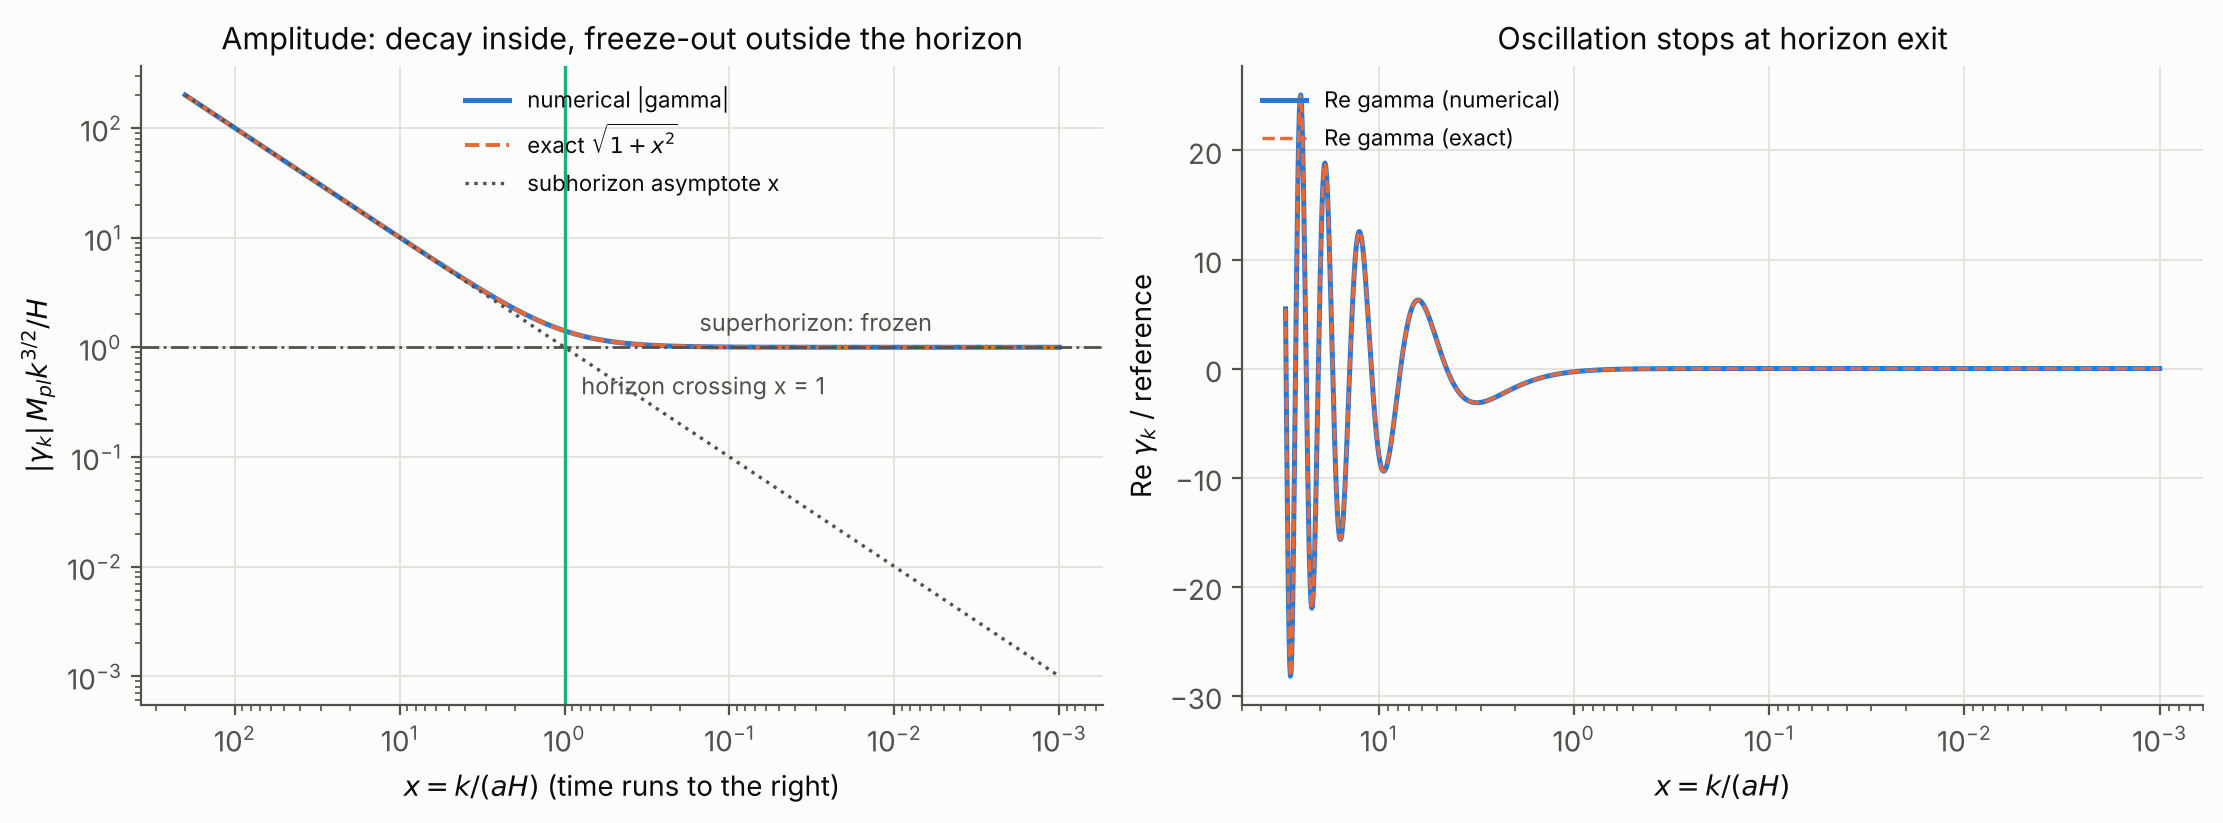

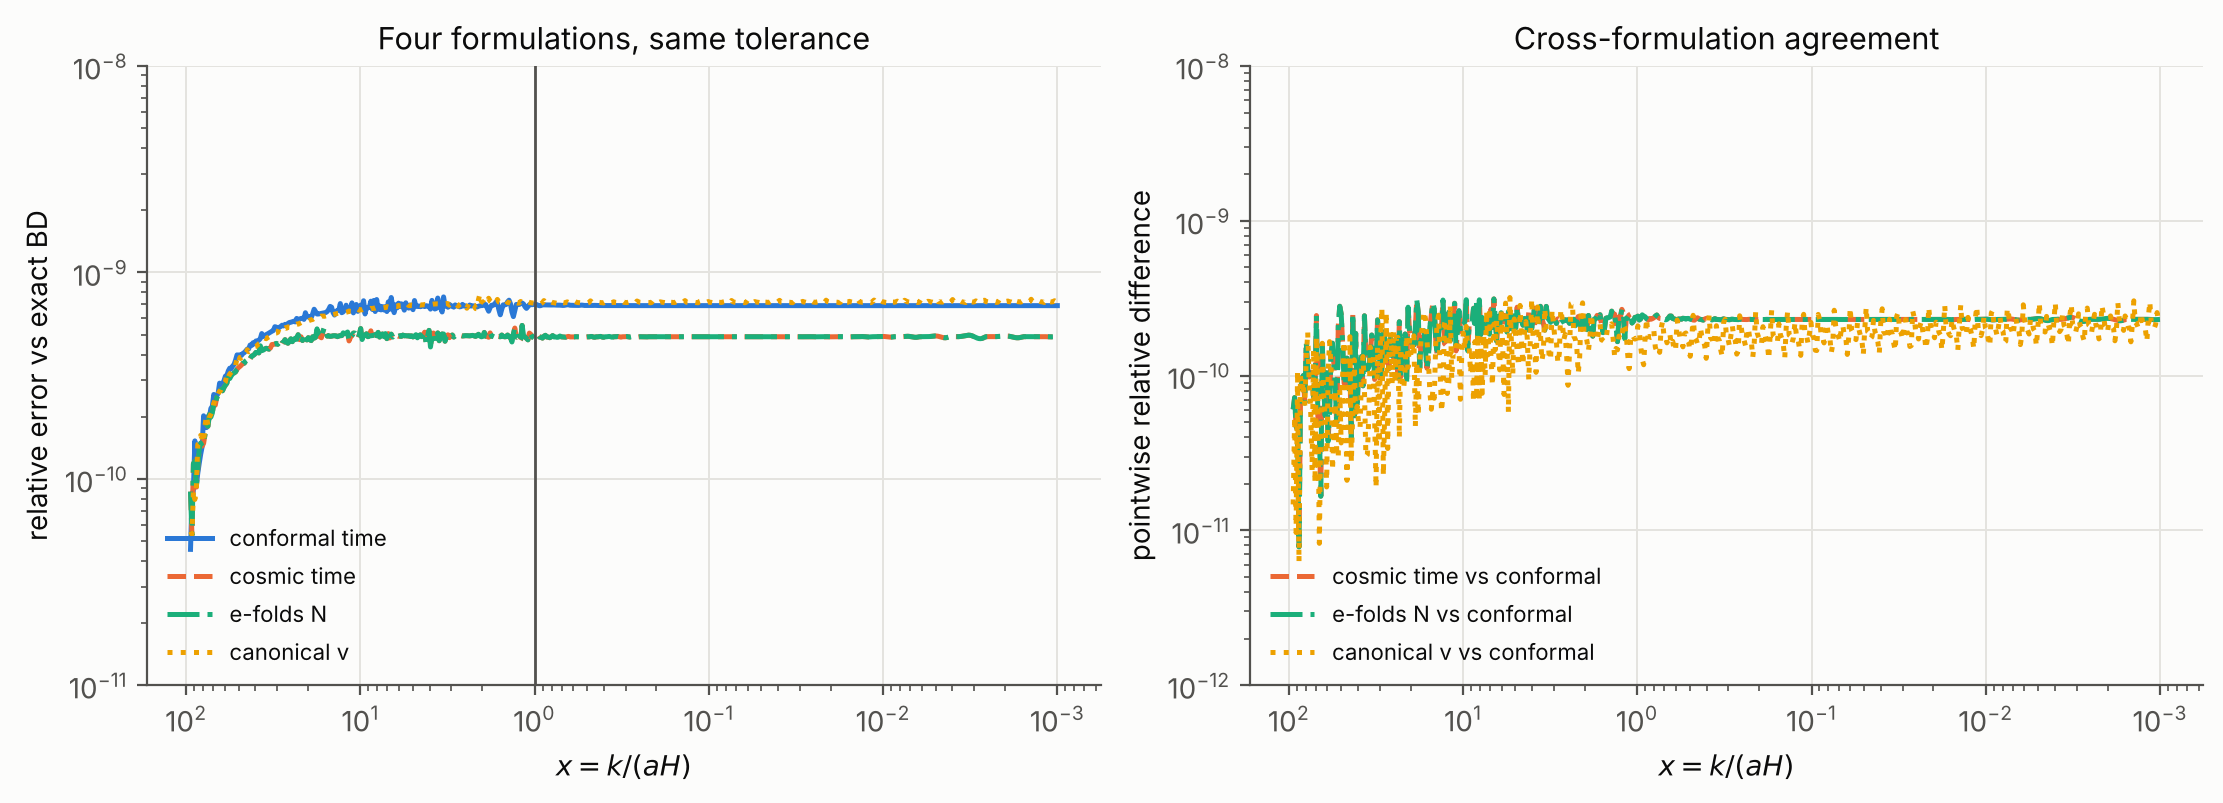

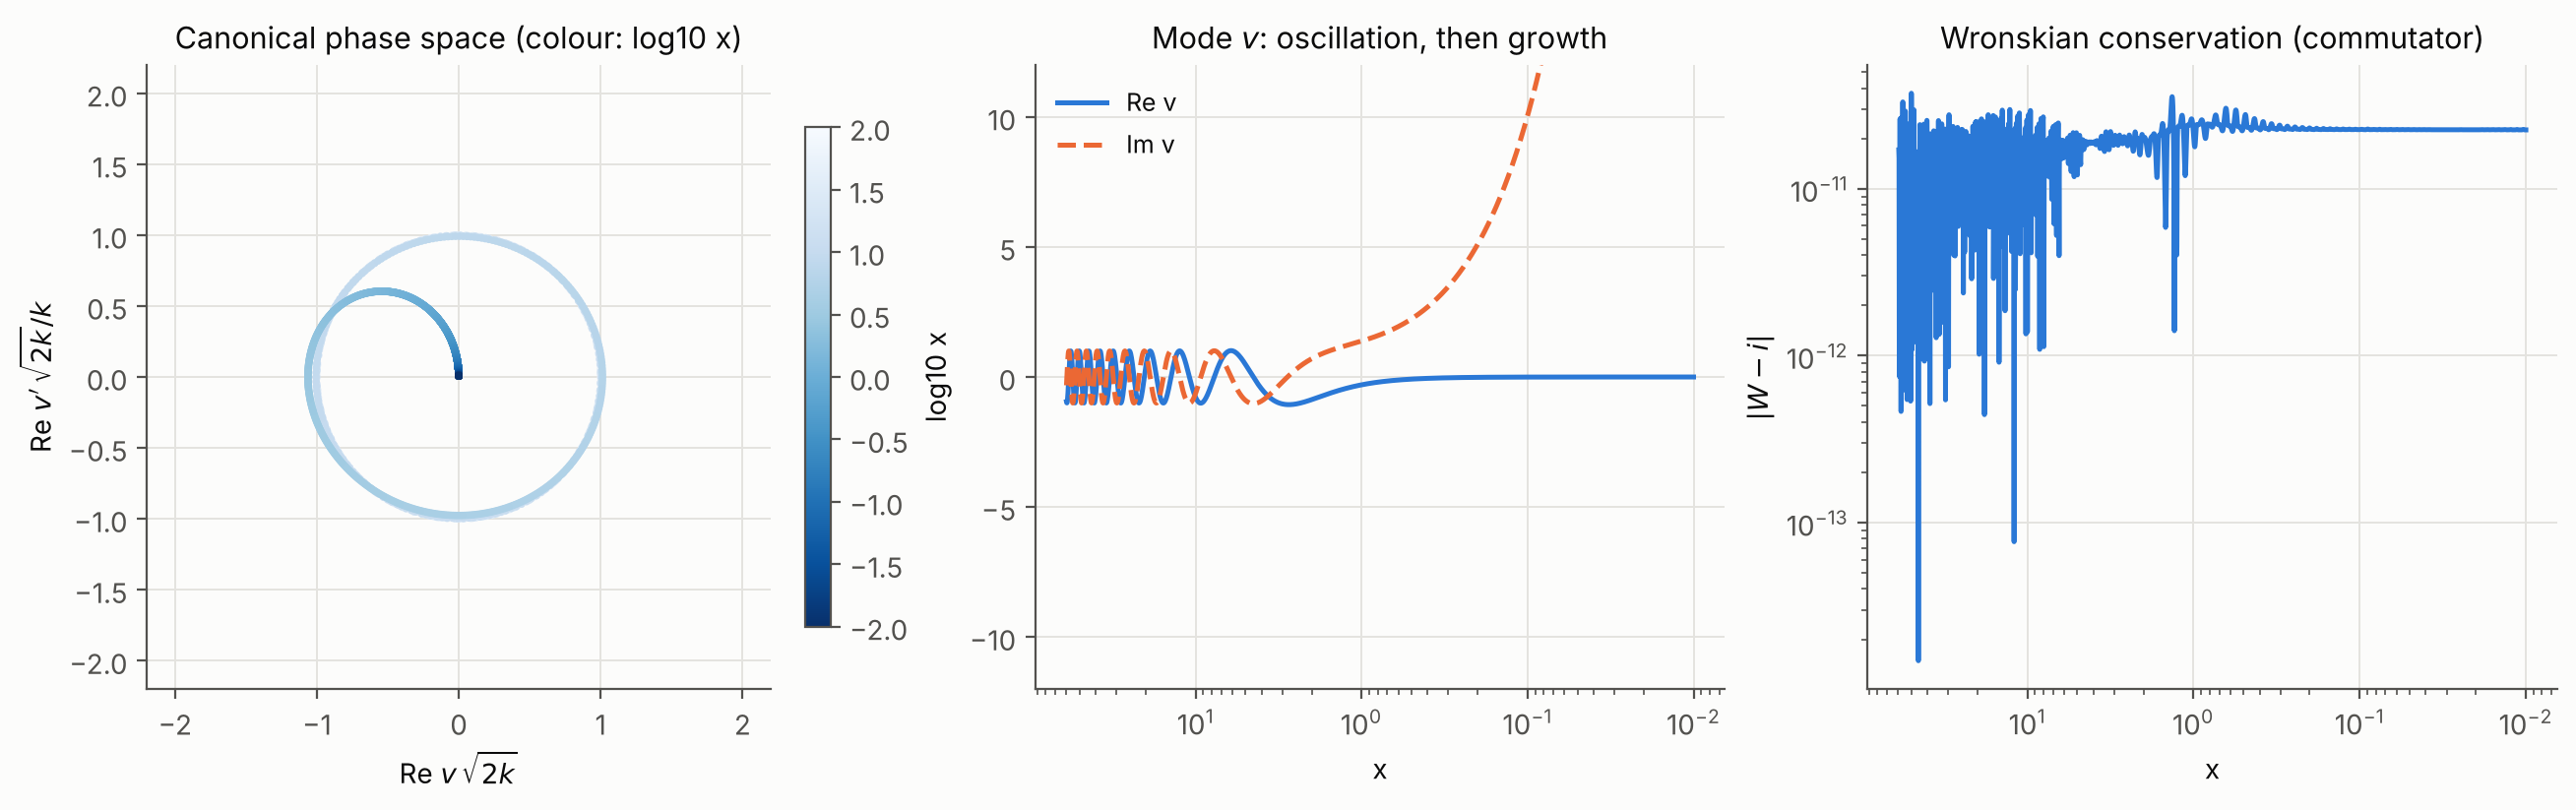

In [3]:
from desitter_perturbations.visualization import mode_plots as mp, phase_space_plots as pp
show(mp.plot_mode_evolution()); show(mp.plot_formulation_comparison()); show(pp.plot_phase_space())

Physical reading: while $x=k/(aH)\gg1$ the mode oscillates and its amplitude falls as $1/a$ (the physical wavelength is inside the Hubble radius);
for $x\ll1$ the gradient term is negligible, $\gamma_k\to$ const, and the amplitude is frozen. Scalar-field mode equations are used only as a mathematical analogy.